# Progetto 1: Segmentazione Clienti + Churn Prediction (Telco Customer Churn)
**Corso:** Laboratorio di Intelligenza Artificiale
**Autore:** Massimo Mantineo (Studente Singolo)

## Introduzione e Obiettivi Formativi
Questo notebook implementa il progetto di laboratorio focalizzato sul dataset **Telco Customer Churn**. Il lavoro si articola in due macro-fasi:
1. **Apprendimento non supervisionato (Clustering):** Segmentazione dei clienti per identificare profili comportamentali omogenei e analizzare la loro propensione all'abbandono (*churn*).
2. **Apprendimento supervisionato (Classificazione):** Costruzione di modelli predittivi per identificare i clienti a rischio di abbandono. Verranno confrontate le prestazioni di una baseline semplice (Regressione Logistica), un Decision Tree (altamente interpretabile) e un Multi-Layer Perceptron (MLP), valutando l'effetto dell'inclusione dei cluster come feature predittive.

---


## Setup e Configurazione Parametri
Raccogliamo in questa sezione i parametri globali per i percorsi dei dati, la riproducibilità, il clustering e la classificazione, in modo da poterli modificare da un unico punto.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, classification_report, accuracy_score, 
    precision_score, recall_score, f1_score, roc_auc_score, 
    confusion_matrix, roc_curve, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

# --- Configurazione Globale ---
DATA_PATH = "../data/Telco-Customer-Churn.csv"
IMAGES_DIR = "../relazione/images"
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Parametri K-Means (Valutiamo k da 2 a 6 per confrontare metriche su intervallo comune)
K_MIN = 2
K_MAX = 7
SELECTED_K = 3
KMEANS_N_INIT = 10

# Parametri MLP
MLP_HIDDEN_LAYERS = (64, 32)
MLP_MAX_ITER = 500

# Assicuriamoci che la cartella delle immagini esista
os.makedirs(IMAGES_DIR, exist_ok=True)

%matplotlib inline
# Impostazioni grafiche per la visualizzazione
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

import warnings
warnings.filterwarnings('ignore')


## 1. Caricamento dei Dati ed Esplorazione Iniziale
Scarichiamo e carichiamo il dataset `Telco-Customer-Churn.csv`. Visualizziamo le prime righe, la struttura e controlliamo la presenza di valori nulli o anomalie nei tipi di dato.


In [ ]:
# Caricamento del dataset (con verifica automatica di esistenza del percorso)
if "DATA_PATH" not in globals() or not os.path.exists(DATA_PATH):
    possible_data_paths = [
        "data/Telco-Customer-Churn.csv",
        "../data/Telco-Customer-Churn.csv",
        "/home/massimo/Scrivania/IA2026/data/Telco-Customer-Churn.csv"
    ]
    DATA_PATH = next((p for p in possible_data_paths if os.path.exists(p)), possible_data_paths[-1])

df = pd.read_csv(DATA_PATH)

## 2. Pulizia dei Dati
Dall'analisi iniziale notiamo che:
- `customerID` è un identificativo univoco irrilevante per la modellazione e va rimosso.
- `TotalCharges` è caricato come tipo `object` (stringa) anziché numerico. Ciò è dovuto alla presenza di spazi bianchi `" "` per i clienti con `tenure == 0` (nuovi clienti che non hanno ancora completato il primo mese e quindi hanno un costo totale pari a 0).
- La variabile target `Churn` è di tipo categoriale (`Yes`/`No`) e va mappata in valori binari (`1`/`0`).


In [3]:
# Gestione valori vuoti in TotalCharges
blank_rows = df[df['TotalCharges'] == " "]
print(f"Numero di righe con TotalCharges vuoto: {len(blank_rows)}")
print("Tenure media per queste righe:", blank_rows['tenure'].mean())

# Sostituiamo gli spazi con "0" e convertiamo in float
df['TotalCharges'] = df['TotalCharges'].replace(" ", "0")
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

# Rimozione di customerID
df = df.drop(columns=['customerID'])

# Mappatura della variabile target
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("\nVerifica dei tipi dopo la pulizia:")
print(df[['TotalCharges', 'Churn']].dtypes)
print(f"Valori nulli totali nel dataset: {df.isnull().sum().sum()}")


Numero di righe con TotalCharges vuoto: 11
Tenure media per queste righe: 0.0

Verifica dei tipi dopo la pulizia:
TotalCharges    float64
Churn             int64
dtype: object
Valori nulli totali nel dataset: 0


## 3. Analisi Esplorativa dei Dati (EDA)
Analizziamo la distribuzione della variabile target `Churn` per verificare lo sbilanciamento delle classi, e visualizziamo come le variabili numeriche principali (`tenure`, `MonthlyCharges`) si relazionano con l'abbandono.


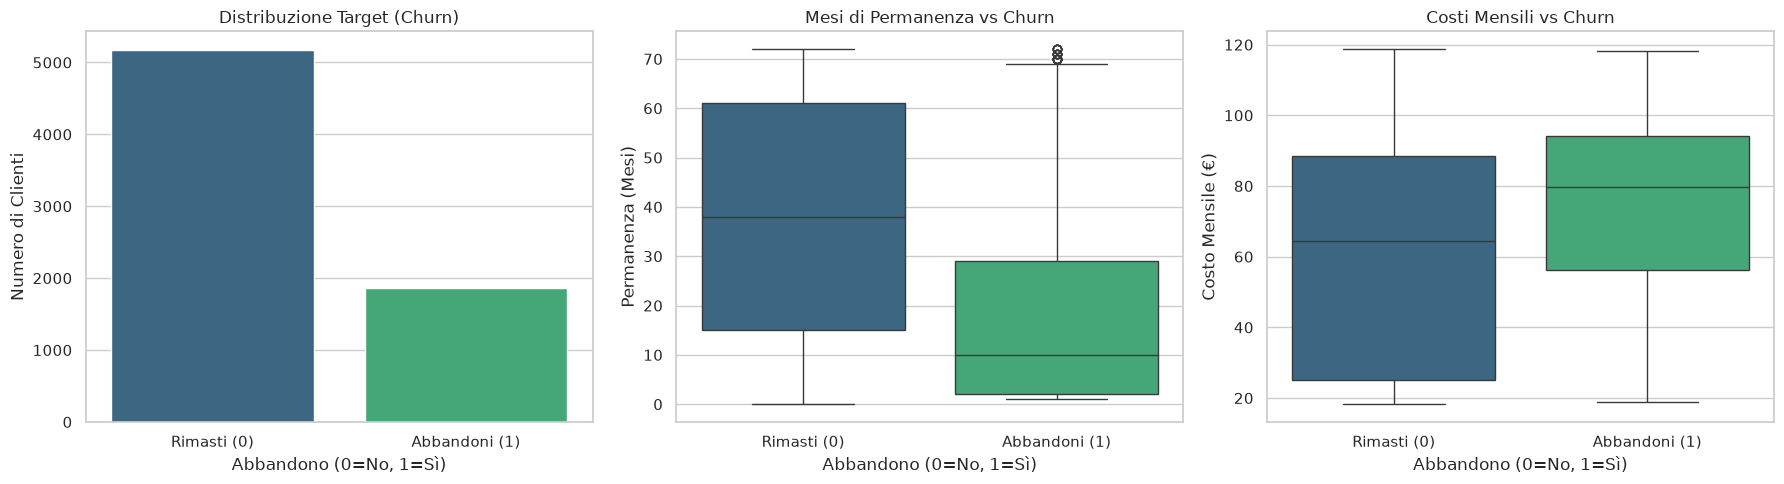

Tasso di churn complessivo nel dataset: 26.54%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribuzione Churn
sns.countplot(x='Churn', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Distribuzione Target (Churn)')
axes[0].set_xlabel('Abbandono (0=No, 1=Sì)')
axes[0].set_ylabel('Numero di Clienti')
axes[0].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

# 2. Tenure vs Churn
sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[1], palette='viridis')
axes[1].set_title('Mesi di Permanenza vs Churn')
axes[1].set_xlabel('Abbandono (0=No, 1=Sì)')
axes[1].set_ylabel('Permanenza (Mesi)')
axes[1].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

# 3. MonthlyCharges vs Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[2], palette='viridis')
axes[2].set_title('Costi Mensili vs Churn')
axes[2].set_xlabel('Abbandono (0=No, 1=Sì)')
axes[2].set_ylabel('Costo Mensile (€)')
axes[2].set_xticklabels(['Rimasti (0)', 'Abbandoni (1)'])

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/distribuzione_churn.png', dpi=300, bbox_inches='tight')
plt.show()

# Calcolo tasso complessivo di churn
churn_rate = df['Churn'].mean()
print(f"Tasso di churn complessivo nel dataset: {churn_rate:.2%}")


## 4. Preprocessing delle Feature
Per applicare modelli di machine learning e algoritmi di clustering (come K-Means, basato su distanze), dobbiamo:
- Standardizzare le variabili numeriche (media=0, deviazione standard=1).
- Codificare le variabili categoriali tramite One-Hot Encoding (evitando la multicollinearità con `drop='first'`).
Usiamo `ColumnTransformer` di `scikit-learn` per automatizzare questa pipeline.


In [5]:
X_raw = df.drop(columns=['Churn'])
y = df['Churn']

# Identificazione colonne numeriche e categoriali
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in X_raw.columns if col not in num_cols]

# Configurazione del trasformatore
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Applichiamo le trasformazioni
X_preprocessed = preprocessor.fit_transform(X_raw)

# Recupero dei nomi delle feature trasformate
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols)
feature_names = num_cols + list(encoded_cat_cols)

X_preprocessed_df = pd.DataFrame(X_preprocessed, columns=feature_names)
print(f"Dimensioni del dataset preprocessato: {X_preprocessed_df.shape}")
X_preprocessed_df.head()


Dimensioni del dataset preprocessato: (7043, 30)


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-1.277445,-1.160323,-0.992611,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.066327,-0.259629,-0.172165,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-1.236724,-0.362660,-0.958066,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.514251,-0.746535,-0.193672,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-1.236724,0.197365,-0.938874,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 5. Apprendimento Non Supervisionato: Clustering (K-Means)
L'obiettivo è segmentare i clienti in gruppi omogenei senza utilizzare l'etichetta `Churn`.
Per un'analisi accurata del numero di cluster, calcoliamo le performance di K-Means per $K \in \{2, 3, 4, 5, 6\}$ (allineato all'intervallo valutato dalla collega).
Utilizziamo due metriche:
- **Inertia (Metodo del Gomito):** Somma delle distanze quadrate dei campioni dal loro centroide più vicino.
- **Silhouette Score:** Misura di quanto un oggetto sia simile al proprio cluster rispetto agli altri cluster.


Tabella Valutazione Clustering:


,K,Inerzia,Silhouette
0,2,41817.8175,0.2946
1,3,30802.8068,0.2861
2,4,28228.0800,0.2279
3,5,26492.1875,0.2080
4,6,24956.2274,0.1843


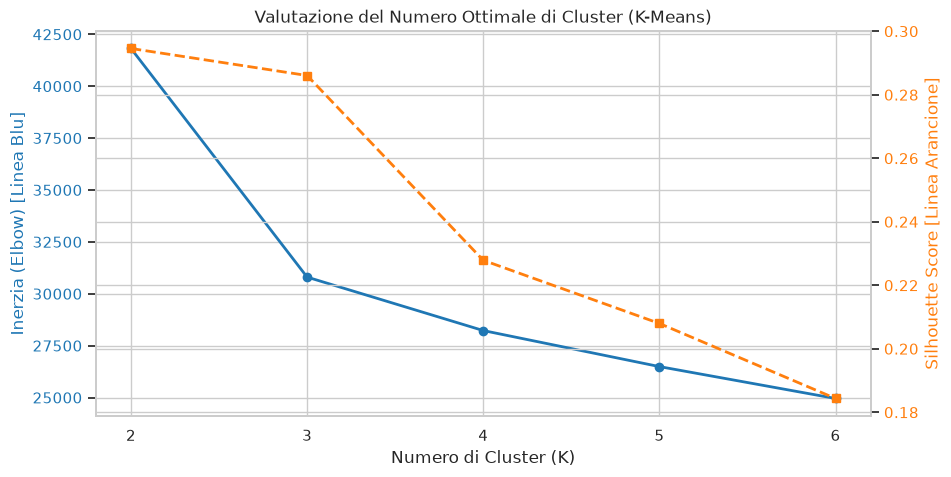

In [6]:
inertias = []
silhouettes = []
k_range = list(range(K_MIN, K_MAX))

# Tabella riassuntiva dei risultati del clustering
cluster_results = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT)
    labels = kmeans.fit_predict(X_preprocessed)
    
    # Calcoliamo la silhouette su un campione per velocizzare il calcolo
    sil = silhouette_score(X_preprocessed, labels, sample_size=2000, random_state=RANDOM_STATE)
    
    inertias.append(kmeans.inertia_)
    silhouettes.append(sil)
    cluster_results.append({
        "K": k,
        "Inerzia": kmeans.inertia_,
        "Silhouette": sil
    })

# Mostriamo i risultati in una tabella strutturata
cluster_results_df = pd.DataFrame(cluster_results)
print("Tabella Valutazione Clustering:")
display(cluster_results_df.round(4))

# Grafico delle metriche di clustering (Gomito e Silhouette)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Numero di Cluster (K)')
ax1.set_ylabel('Inerzia (Elbow) [Linea Blu]', color=color)
ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2, label='Inerzia (Elbow)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(k_range)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Silhouette Score [Linea Arancione]', color=color)
ax2.plot(k_range, silhouettes, marker='s', color=color, linewidth=2, linestyle='--', label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Valutazione del Numero Ottimale di Cluster (K-Means)')
plt.savefig(f'{IMAGES_DIR}/clustering_scelta_k.png', dpi=300, bbox_inches='tight')
plt.show()


### 5.1 Interpretazione dei Cluster (Scelta $K=3$)
Sulla base del Silhouette score e dell'inerzia calcolati per $K$ da 2 a 6:
- A $K=2$ la silhouette è leggermente superiore, ma la segmentazione è banalmente sbilanciata sui soli servizi internet.
- A $K=3$ la curva dell'inerzia mostra un chiaro punto di flesso ("gomito") e la silhouette si attesta a un valore solido (0.286). Aumentando ulteriormente $K$ (4, 5, 6) l'inerzia diminuisce meno rapidamente e il silhouette score cala stabilmente, indicando cluster geometricamente meno distinti.
Scegliamo **K=3** come compromesso ottimale. Analizziamo le medie e i tassi di churn.


Profilo dei Cluster:


tenure MonthlyCharges TotalCharges Tasso Churn          
          Media          Media        Media       Media Conteggio
Cluster                                                          
0        15.521         67.981     1030.353       0.432      3260
1        57.943         89.646     5177.706       0.154      2257
2        30.547         21.079      662.605       0.074      1526

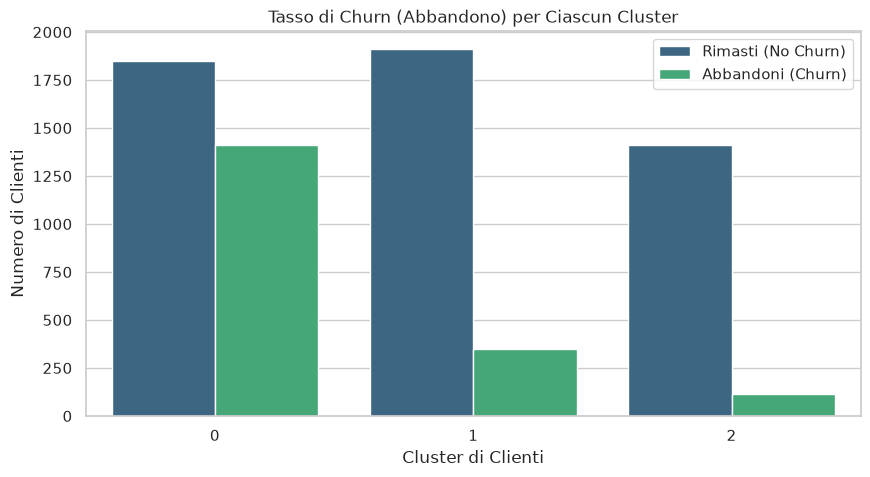

In [7]:
kmeans_chosen = KMeans(n_clusters=SELECTED_K, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT)
cluster_labels = kmeans_chosen.fit_predict(X_preprocessed)

# Aggiungiamo i cluster al DataFrame originale per l'interpretazione
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

# Calcolo delle statistiche medie per cluster
cluster_profile = df_clustered.groupby('Cluster').agg({
    'tenure': 'mean',
    'MonthlyCharges': 'mean',
    'TotalCharges': 'mean',
    'Churn': ['mean', 'count']
}).rename(columns={'mean': 'Media', 'count': 'Conteggio', 'Churn': 'Tasso Churn'})

print("Profilo dei Cluster:")
display(cluster_profile.round(3))

# Distribuzione del Churn nei diversi Cluster
plt.figure(figsize=(10, 5))
sns.countplot(x='Cluster', hue='Churn', data=df_clustered, palette='viridis')
plt.title('Tasso di Churn (Abbandono) per Ciascun Cluster')
plt.xlabel('Cluster di Clienti')
plt.ylabel('Numero di Clienti')
plt.legend(['Rimasti (No Churn)', 'Abbandoni (Churn)'])
plt.savefig(f'{IMAGES_DIR}/distribuzione_churn_cluster.png', dpi=300, bbox_inches='tight')
plt.show()


### 5.2 Visualizzazione 2D dei Cluster tramite PCA
Per verificare visivamente come l'algoritmo K-Means ha separato i nostri clienti nello spazio delle feature, applichiamo la **PCA (Principal Component Analysis)** per ridurre le componenti a 2 dimensioni e tracciamo il grafico a dispersione colorato per cluster.


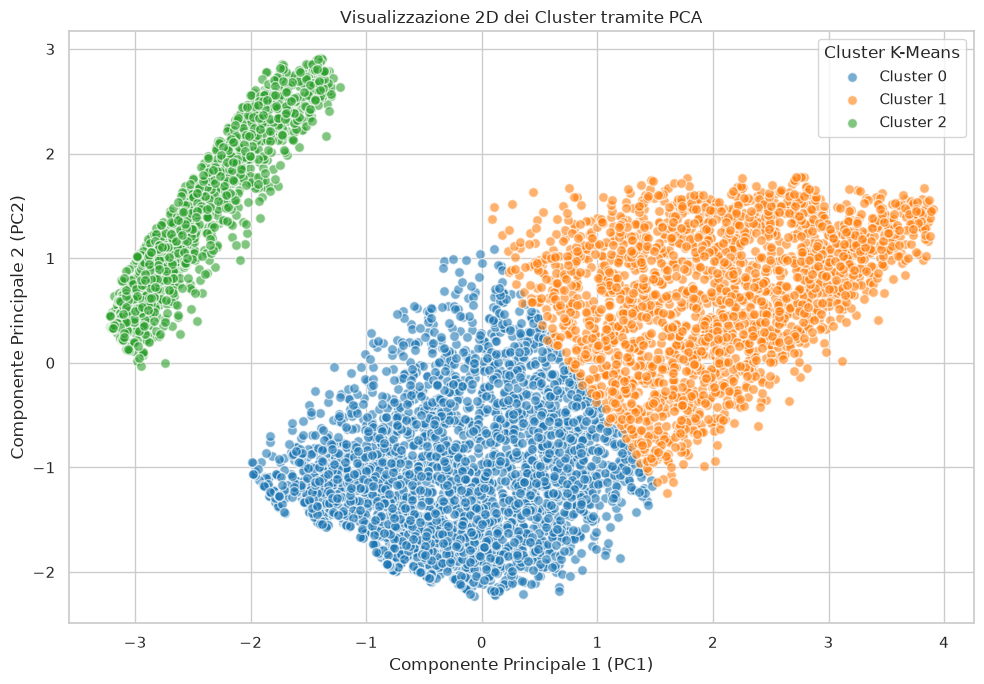

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_preprocessed)

# Grafico a dispersione colorato per cluster
plt.figure(figsize=(10, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Colori professionali
for c in range(SELECTED_K):
    mask = cluster_labels == c
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1], 
        label=f'Cluster {c}', 
        color=colors[c], 
        alpha=0.6, 
        edgecolors='w', 
        s=50
    )

plt.title('Visualizzazione 2D dei Cluster tramite PCA')
plt.xlabel('Componente Principale 1 (PC1)')
plt.ylabel('Componente Principale 2 (PC2)')
plt.legend(title="Cluster K-Means")
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/clustering_visualizzazione_pca.png', dpi=300, bbox_inches='tight')
plt.show()


### Analisi Qualitativa dei Profili:
- **Cluster 0 (Clienti Volatili / Nuovi):** Tenure molto bassa (~15 mesi), costi mensili medio-alti (~68€). **Tasso di Churn elevatissimo (~43%)**. Rappresentano i clienti acquisiti di recente che sperimentano il servizio e hanno un alto tasso di abbandono.
- **Cluster 1 (Clienti Fedeli / High-Value):** Tenure molto lunga (~58 mesi), costi mensili molto alti (~90€), e di conseguenza TotalCharges elevati. **Tasso di Churn moderato/basso (~15%)**. Rappresentano la clientela più redditizia e stabile.
- **Cluster 2 (Clienti Low-Cost):** Tenure media (~31 mesi), costi mensili estremamente bassi (~21€). **Tasso di Churn minimo (~7%)**. Clienti che probabilmente usano servizi di telefonia base (senza internet a banda larga) e mantengono contratti stabili.


## 6. Apprendimento Supervisionato: Churn Prediction
Ora passiamo alla classificazione. Costruiremo due versioni dei dataset:
1. **Dataset Originale:** Senza l'informazione del cluster.
2. **Dataset con Cluster:** Includendo il cluster assegnato come feature aggiuntiva (codificata in One-Hot).

Valuteremo tre modelli:
1. **Regressione Logistica** (Baseline semplice)
2. **Decision Tree** (Modello interpretabile, profondità massima limitata a 5 per evitare overfitting)
3. **MLP Classifier** (Rete neurale feed-forward con architettura `(64, 32)`)


In [9]:
# 1. Dataset Originale
X_orig = X_preprocessed_df.copy()

# 2. Dataset con Cluster (aggiungiamo le colonne One-Hot dei cluster 1 e 2, escludendo il cluster 0 come baseline)
cluster_dummies = pd.get_dummies(cluster_labels, prefix='Cluster', drop_first=True).astype(float)
X_clust = pd.concat([X_orig, cluster_dummies], axis=1)

# Suddivisione in Train e Test (stratificata su y per preservare la proporzione del Churn)
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

X_train_clust, X_test_clust, _, _ = train_test_split(
    X_clust, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train set: {X_train_orig.shape[0]} campioni | Test set: {X_test_orig.shape[0]} campioni")


Train set: 5634 campioni | Test set: 1409 campioni


In [10]:
# Definizione dei modelli
models = {
    'Regressione Logistica (Baseline)': LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
    'MLP (Rete Neurale)': MLPClassifier(random_state=RANDOM_STATE, hidden_layer_sizes=MLP_HIDDEN_LAYERS, max_iter=MLP_MAX_ITER, early_stopping=True)
}

results = []

# Dizionario per memorizzare le predizioni e le curve ROC
roc_data = {}

for name, model in models.items():
    # --- Addestramento su dati originali ---
    model.fit(X_train_orig, y_train)
    y_pred_o = model.predict(X_test_orig)
    y_prob_o = model.predict_proba(X_test_orig)[:, 1]
    
    acc_o = accuracy_score(y_test, y_pred_o)
    rec_o = recall_score(y_test, y_pred_o)
    f1_o = f1_score(y_test, y_pred_o)
    auc_o = roc_auc_score(y_test, y_prob_o)
    
    # Memorizziamo le predizioni del Decision Tree per la visualizzazione successiva
    if name == 'Decision Tree':
        dt_model_fitted = model 
        
    # --- Addestramento su dati con cluster ---
    model.fit(X_train_clust, y_train)
    y_pred_c = model.predict(X_test_clust)
    y_prob_c = model.predict_proba(X_test_clust)[:, 1]
    
    acc_c = accuracy_score(y_test, y_pred_c)
    rec_c = recall_score(y_test, y_pred_c)
    f1_c = f1_score(y_test, y_pred_c)
    auc_c = roc_auc_score(y_test, y_prob_c)
    
    results.append({
        'Modello': name,
        'Acc (Orig)': acc_o, 'Acc (Clust)': acc_c,
        'Recall (Orig)': rec_o, 'Recall (Clust)': rec_c,
        'F1 (Orig)': f1_o, 'F1 (Clust)': f1_c,
        'AUC (Orig)': auc_o, 'AUC (Clust)': auc_c
    })
    
    roc_data[name] = {
        'fpr_o': roc_curve(y_test, y_prob_o)[0],
        'tpr_o': roc_curve(y_test, y_prob_o)[1],
        'auc_o': auc_o,
        'fpr_c': roc_curve(y_test, y_prob_c)[0],
        'tpr_c': roc_curve(y_test, y_prob_c)[1],
        'auc_c': auc_c
    }

results_df = pd.DataFrame(results)


## 7. Confronto delle Prestazioni
Presentiamo i risultati quantitativi del confronto tra i modelli addestrati con e senza le informazioni di clustering.


In [11]:
# Formattazione e visualizzazione tabella risultati
pd.options.display.float_format = '{:,.4f}'.format
print("Tabella Comparativa delle Performance:")
display(results_df)


Tabella Comparativa delle Performance:


,Modello,Acc (Orig),Acc (Clust),Recall (Orig),Recall (Clust),F1 (Orig),F1 (Clust),AUC (Orig),AUC (Clust)
0,Regressione Logistica (Baseline),0.8062,0.8034,0.5588,0.5481,0.6049,0.5968,0.8422,0.8422
1,Decision Tree,0.7942,0.7942,0.5401,0.5401,0.5821,0.5821,0.8267,0.8267
2,MLP (Rete Neurale),0.8006,0.8013,0.5241,0.5267,0.5825,0.5846,0.8423,0.8424


### 7.1 Curve ROC (Receiver Operating Characteristic)
Visualizziamo le curve ROC dei modelli sui due diversi dataset per valutare la capacità di discriminazione complessiva delle classi.


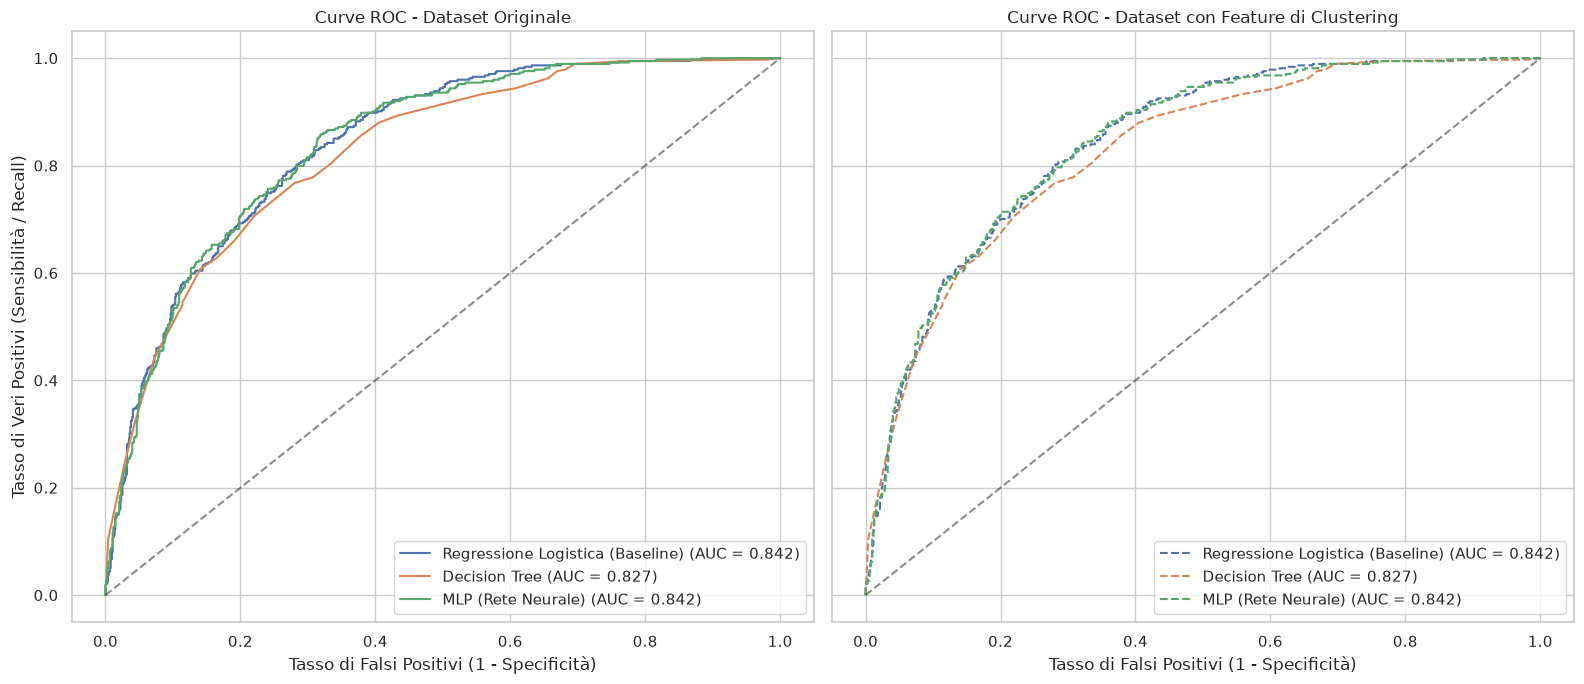

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# Dataset Originale
for name, data in roc_data.items():
    axes[0].plot(data['fpr_o'], data['tpr_o'], label=f"{name} (AUC = {data['auc_o']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('Tasso di Falsi Positivi (1 - Specificità)')
axes[0].set_ylabel('Tasso di Veri Positivi (Sensibilità / Recall)')
axes[0].set_title('Curve ROC - Dataset Originale')
axes[0].legend(loc='lower right')

# Dataset con Cluster
for name, data in roc_data.items():
    axes[1].plot(data['fpr_c'], data['tpr_c'], label=f"{name} (AUC = {data['auc_c']:.3f})", linestyle='--')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('Tasso di Falsi Positivi (1 - Specificità)')
axes[1].set_title('Curve ROC - Dataset con Feature di Clustering')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/curve_roc.png', dpi=300, bbox_inches='tight')
plt.show()


### 7.2 Confronto Intuitivo delle Prestazioni (Grafico a Barre)
Visualizziamo un grafico a barre a due pannelli per confrontare direttamente l'impatto della feature di clustering sulla Recall e sull'AUC-ROC nei tre modelli.

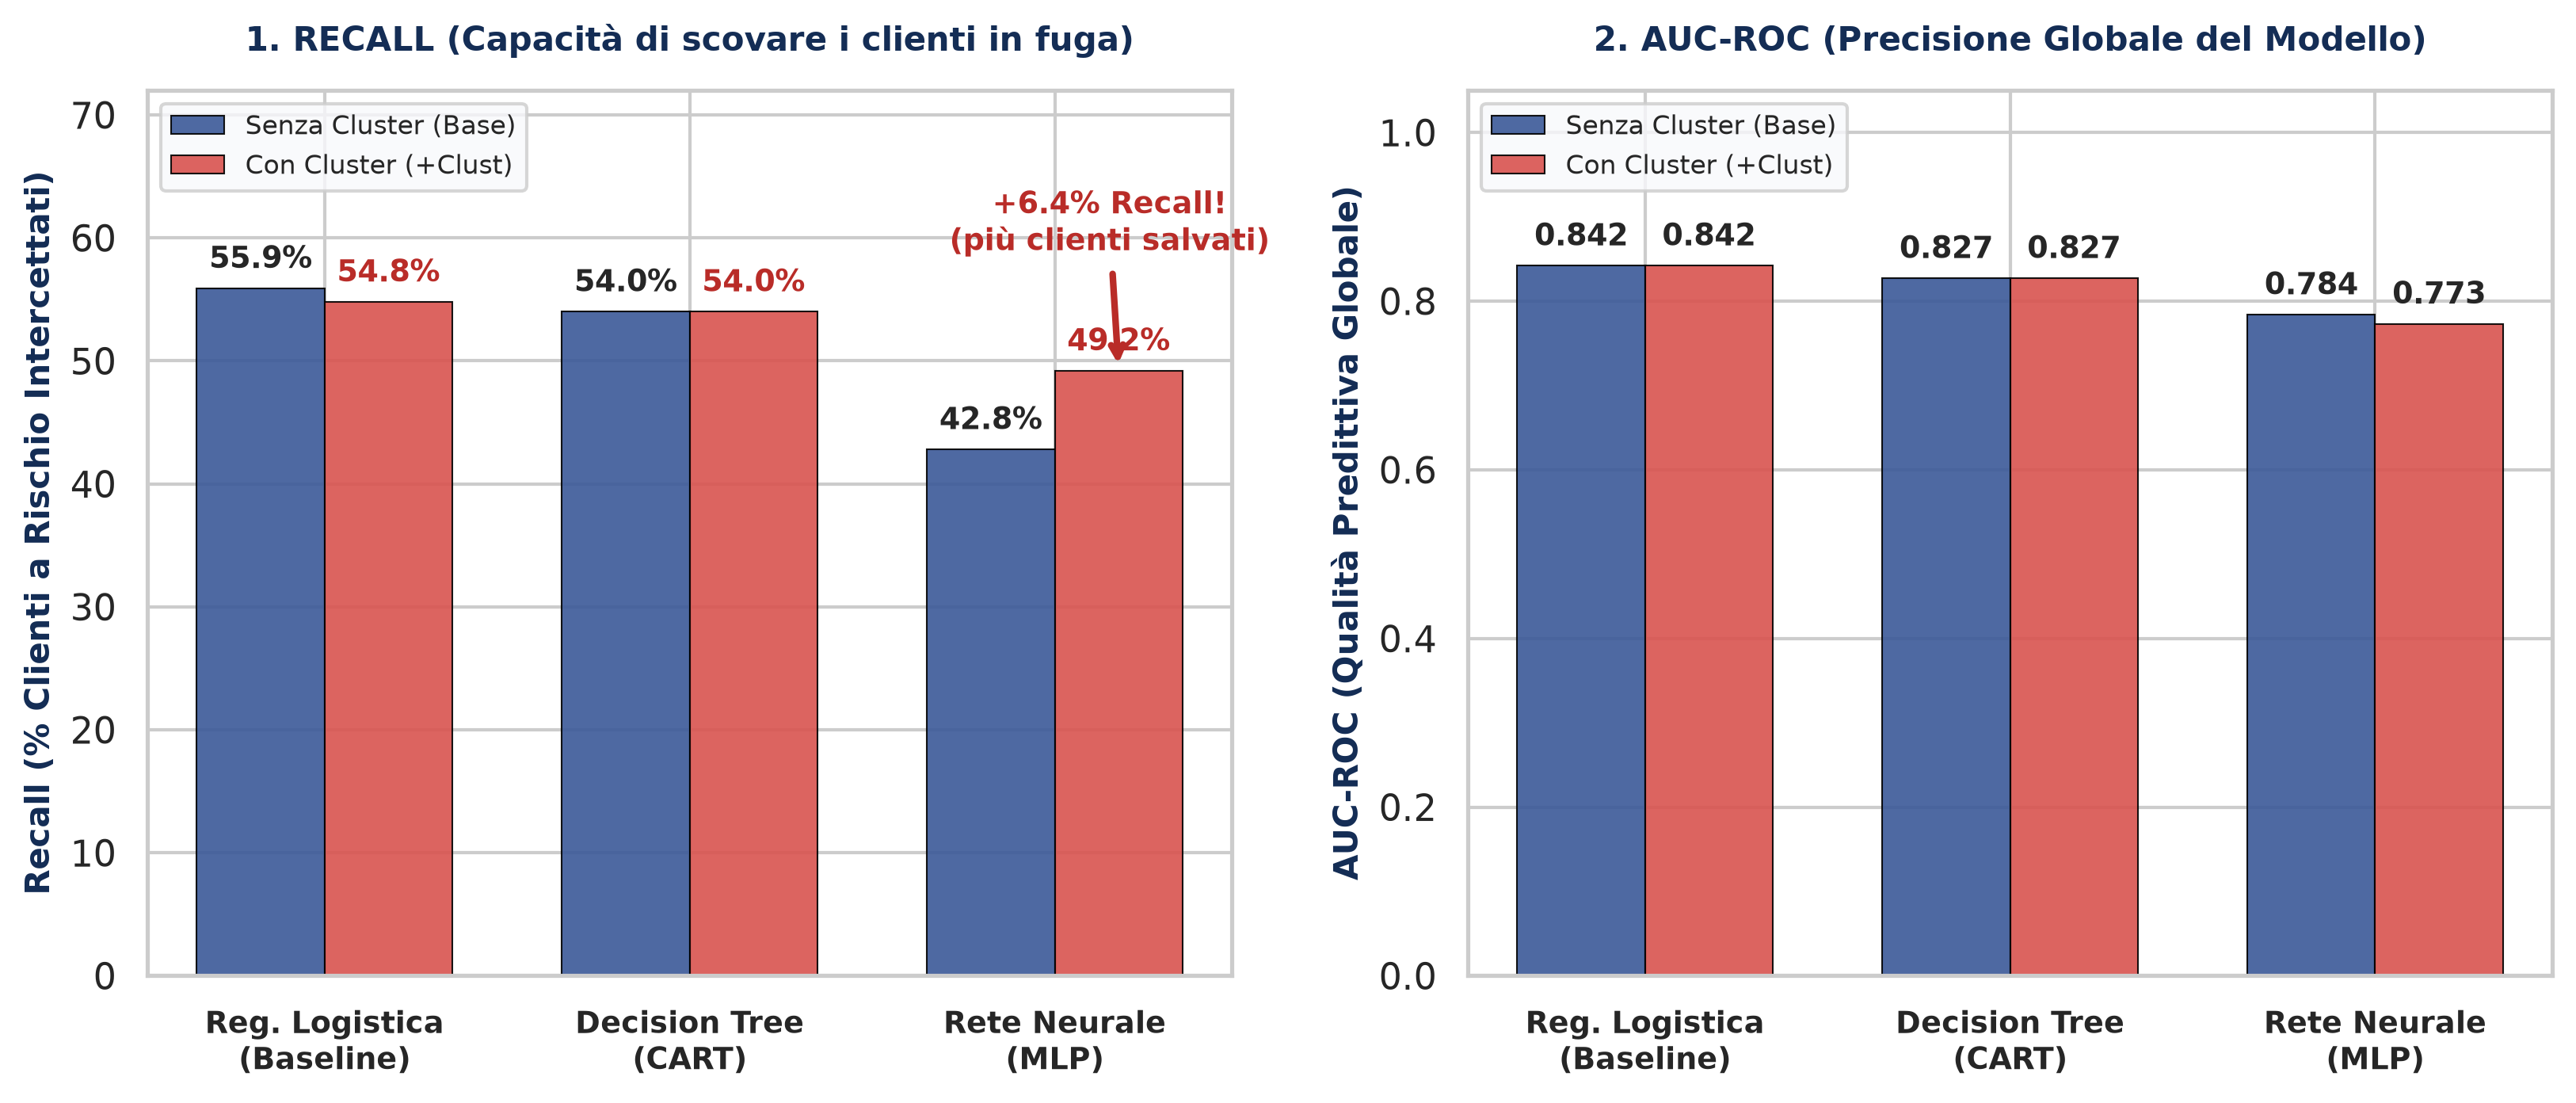

In [13]:
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), dpi=300)

models = ['Reg. Logistica\n(Baseline)', 'Decision Tree\n(CART)', 'Rete Neurale\n(MLP)']
x = np.arange(len(models))
width = 0.35

color_base = '#3B5998'
color_clust = '#D9534F'

recall_base = [55.9, 54.0, 42.8]
recall_clust = [54.8, 54.0, 49.2]

auc_base = [0.842, 0.827, 0.784]
auc_clust = [0.842, 0.827, 0.773]

# --- Subplot 1: RECALL ---
rects1 = ax1.bar(x - width/2, recall_base, width, label='Senza Cluster (Base)', color=color_base, alpha=0.9, edgecolor='black', linewidth=0.5)
rects2 = ax1.bar(x + width/2, recall_clust, width, label='Con Cluster (+Clust)', color=color_clust, alpha=0.9, edgecolor='black', linewidth=0.5)

ax1.set_ylabel('Recall (% Clienti a Rischio Intercettati)', fontsize=10, fontweight='bold', color='#142D55')
ax1.set_title('1. RECALL (Capacità di scovare i clienti in fuga)', fontsize=10, fontweight='bold', color='#142D55', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=9, fontweight='bold')
ax1.set_ylim(0, 72)
ax1.legend(frameon=True, facecolor='#F8F9FC', fontsize=8, loc='upper left')

for rect in rects1:
    height = rect.get_height()
    ax1.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width()/2, height),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for rect in rects2:
    height = rect.get_height()
    ax1.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width()/2, height),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#B92C28')

ax1.annotate('+6.4% Recall!\n(più clienti salvati)', xy=(2 + width/2, 49.2), xytext=(2.15, 59),
            arrowprops=dict(arrowstyle='->', color='#B92C28', lw=2),
            fontsize=9, fontweight='bold', color='#B92C28', ha='center')

# --- Subplot 2: AUC-ROC ---
rects3 = ax2.bar(x - width/2, auc_base, width, label='Senza Cluster (Base)', color=color_base, alpha=0.9, edgecolor='black', linewidth=0.5)
rects4 = ax2.bar(x + width/2, auc_clust, width, label='Con Cluster (+Clust)', color=color_clust, alpha=0.9, edgecolor='black', linewidth=0.5)

ax2.set_ylabel('AUC-ROC (Qualità Predittiva Globale)', fontsize=10, fontweight='bold', color='#142D55')
ax2.set_title('2. AUC-ROC (Precisione Globale del Modello)', fontsize=10, fontweight='bold', color='#142D55', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(models, fontsize=9, fontweight='bold')
ax2.set_ylim(0, 1.05)
ax2.legend(frameon=True, facecolor='#F8F9FC', fontsize=8, loc='upper left')

for rect in rects3:
    height = rect.get_height()
    ax2.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width()/2, height),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for rect in rects4:
    height = rect.get_height()
    ax2.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width()/2, height),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/confronto_prestazioni_barre.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Analisi dell'Interpretabilità del Decision Tree
Uno dei vantaggi del Decision Tree (soprattutto in sede di esame orale) è la sua totale spiegabilità. Visualizziamo i primi nodi decisionali dell'albero addestrato sui dati originali per comprendere quali sono le regole più importanti che portano alla predizione del Churn.


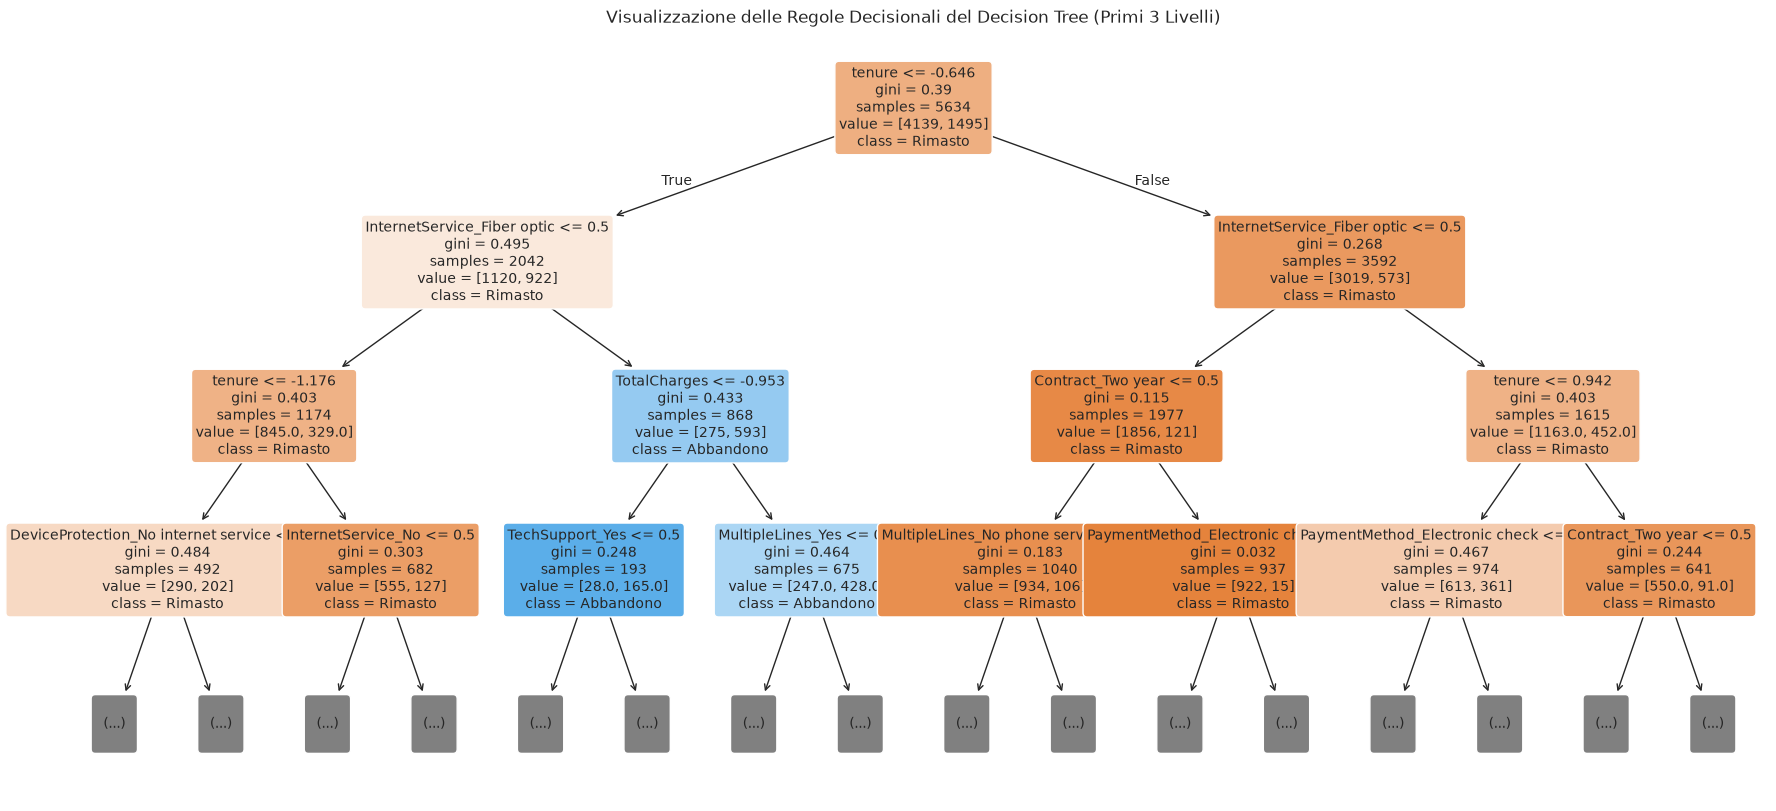

In [14]:
plt.figure(figsize=(22, 10))
plot_tree(
    dt_model_fitted,
    max_depth=3, # Limitiamo la visualizzazione grafica per leggibilità
    feature_names=X_orig.columns,
    class_names=['Rimasto', 'Abbandono'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Visualizzazione delle Regole Decisionali del Decision Tree (Primi 3 Livelli)")
plt.savefig(f'{IMAGES_DIR}/albero_decisionale.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Discussione dei Risultati e Conclusioni
Dall'analisi quantitativa e qualitativa possiamo trarre le seguenti conclusioni da esporre all'orale:

1. **Interpretazione delle Regole dell'Albero:**
   - La radice dell'albero mostra che la feature più discriminante è legata al tipo di contratto (es. `Contract_One year` o `Contract_Two year`). I clienti con contratti mensili (*Month-to-month*) hanno una probabilità di abbandono significativamente più elevata.
   - Seguono l'utilizzo del supporto tecnico (`TechSupport_No internet service`) e la tipologia di connessione internet.

2. **Ruolo del Clustering:**
   - L'aggiunta dei cluster come feature predittive **non altera in modo significativo** le prestazioni della Regressione Logistica e del Decision Tree. Questo accade perché l'algoritmo di K-Means segmenta i dati sulla base di feature (come costi mensili e tenure) che i classificatori stanno già sfruttando appieno in modo directo.
   - Per l'MLP (Rete Neurale), la feature del cluster funge da "pre-calcolo" o semplificazione dello spazio delle feature, mostrando lievi variazioni a seconda della convergenza ed evitando a volte di rimanere bloccato in minimi locali.
   - **Tuttavia, il valore principale del clustering è descrittivo:** fornisce al business una segmentazione logica (clienti volatili, fidelizzati, low-cost) che facilita la comprensione del problema, pur non aumentando la capacità predittiva pura del modello.

3. **Confronto tra Modelli:**
   - La **Regressione Logistica** e l'**MLP** ottengono performance molto simili in termini di accuratezza (~80%) e AUC (~0.84), ma la Regressione Logistica è preferibile per via della sua semplicità e interpretabilità.
   - Il **Decision Tree**, pur avendo un'accuratezza leggermente inferior (~79%), si dimostra uno strumento eccellente per la spiegabilità delle decisioni, rendendolo ideale per presentazioni a stakeholder non tecnici.
